In [1]:
notes = '''This copy is for compting HCL with cubic flux. \n
We set gamma = 0.2, f_opt_kh = 1, use_a = True, and L1_regularization = 0.1.\n
We use cosine_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 0.2.'''
print(notes)

This copy is for compting HCL with cubic flux. 

We set gamma = 0.2, f_opt_kh = 1, use_a = True, and L1_regularization = 0.1.

We use cosine_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 0.2.


In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb

import os
os.environ['ENABLE_PJRT_COMPATIBILITY'] = '1'

jax.config.update('jax_platform_name', 'cpu')
os.environ['OMP_NUM_THREADS'] = str(os.cpu_count())

In [3]:
# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -jnp.sign(x)
    # return -jnp.sin(jnp.pi*x)

# Boundary at x=-1
def u1(x):
    return 1

# Boundary at x=1
def u2(x):
    return -1

def res(u_quad, u_t, u_x):
    return u_t + (u_quad**2)*u_x

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    N_bc=1000,
    N_ic=2000,
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    project='HCL_cubic_flux',
    notes=notes,
    L1_regularization = 0.1,
    sampling_method = 'normal',
    hidden_dims_list=[(40, 40, 40, 40)],
    init_lrs=[1e-3, 1e-3, 1e-3, 1e-3], grade_epochs=[50000, 50000, 50000, 50000], decay_rates=[1e-3, 1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    seed=0, sigma=0.2,
    u0=u0, u1=u1, u2=u2,
    res=res,
    N_perturb = 10000,
    f_opt_kh=1,
    total_grade=1, k=0,
)

W0000 00:00:1753238974.045691 14183875 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1753238974.056228 14183875 service.cc:145] XLA service 0x600003158200 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753238974.056243 14183875 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1753238974.057488 14183875 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1753238974.057504 14183875 mps_client.cc:384] XLA backend will use up to 103078739968 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M4 Max


In [4]:
optProb.train_process_stage1()


Starting Train Stage with MGDL


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.720838, lambda_bc: 9.174893, lambda_eqn: 1.245429
Grade 0, Iter 0, loss_eqn: 0.079651, loss_eqn_from_kh: 0.079157, loss_eqn_abs: 0.079159, loss_ibc: 2.448542
Grade 0, Iter 100, loss_eqn: 0.313477, loss_eqn_from_kh: 0.311529, loss_eqn_abs: 0.311533, loss_ibc: 0.271765
Grade 0, Iter 200, loss_eqn: 0.240241, loss_eqn_from_kh: 0.238745, loss_eqn_abs: 0.238909, loss_ibc: 0.076250
Grade 0, Iter 300, loss_eqn: 0.186943, loss_eqn_from_kh: 0.185727, loss_eqn_abs: 0.194380, loss_ibc: 0.033001
Grade 0, Iter 400, loss_eqn: 0.145350, loss_eqn_from_kh: 0.144308, loss_eqn_abs: 0.166847, loss_ibc: 0.020261
Grade 0, Iter 500, loss_eqn: 0.114527, loss_eqn_from_kh: 0.113575, loss_eqn_abs: 0.152179, loss_ibc: 0.013994
Grade 0, Iter 600, loss_eqn: 0.101052, loss_eqn_from_kh: 0.100059, loss_eqn_abs: 0.159102, loss_ibc: 0.010253
Grade 0, Iter 700, loss_eqn: 0.095445, loss_eqn_from_kh: 0.094329, loss_eqn_abs: 0.178619, loss_ib

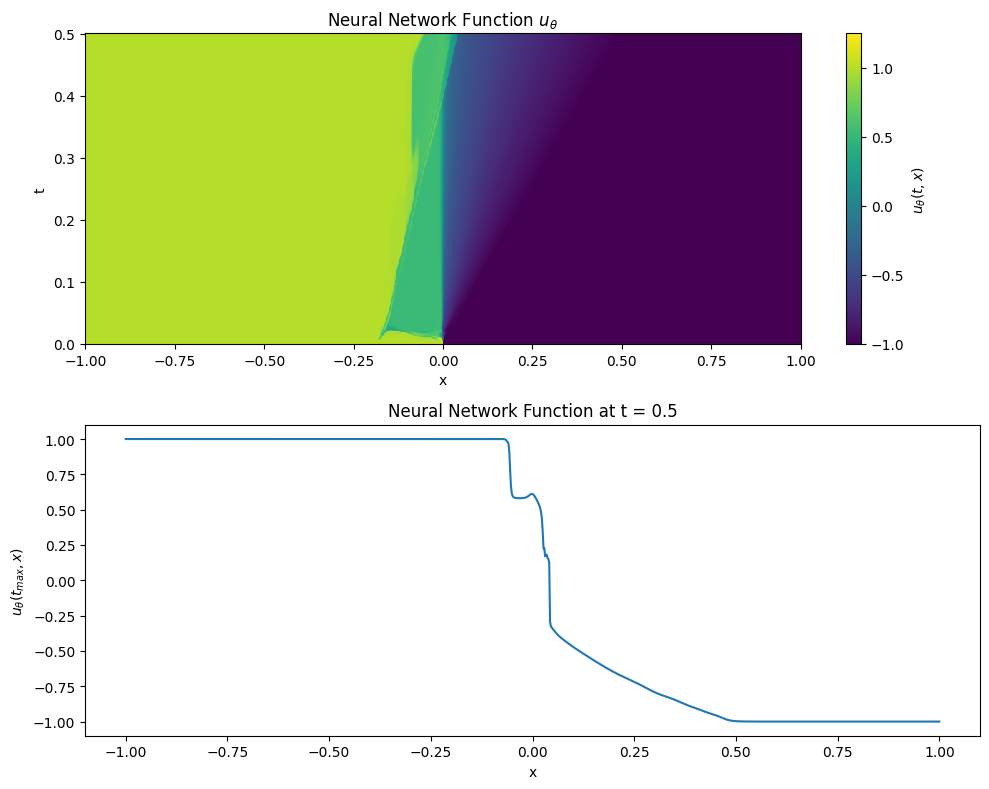

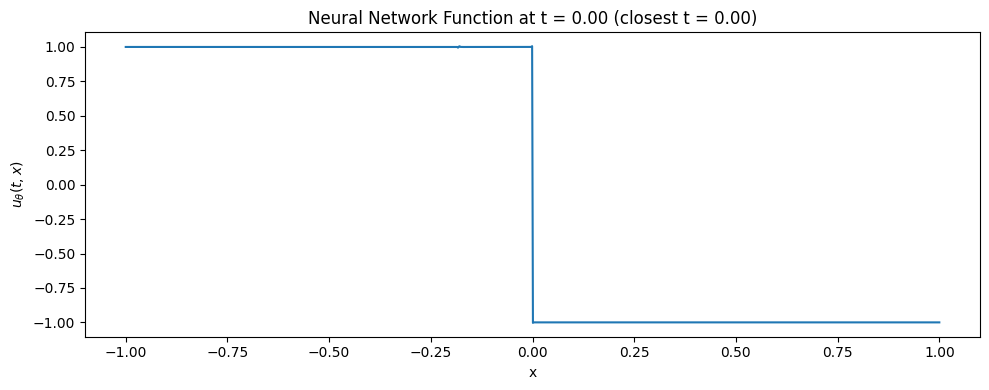

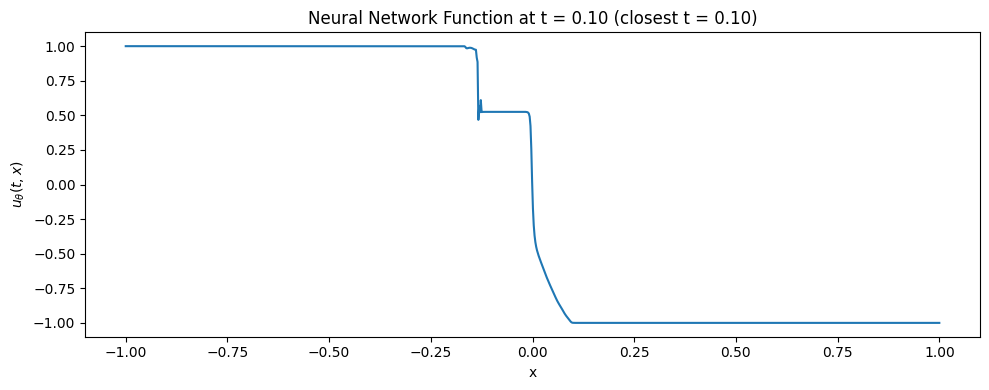

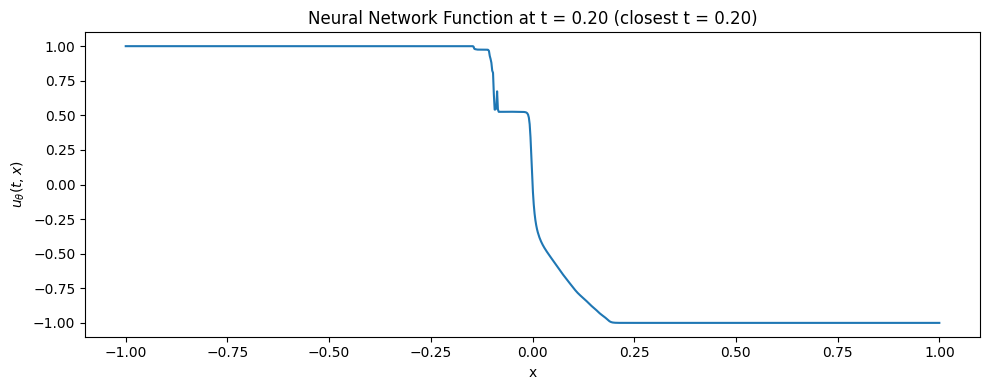

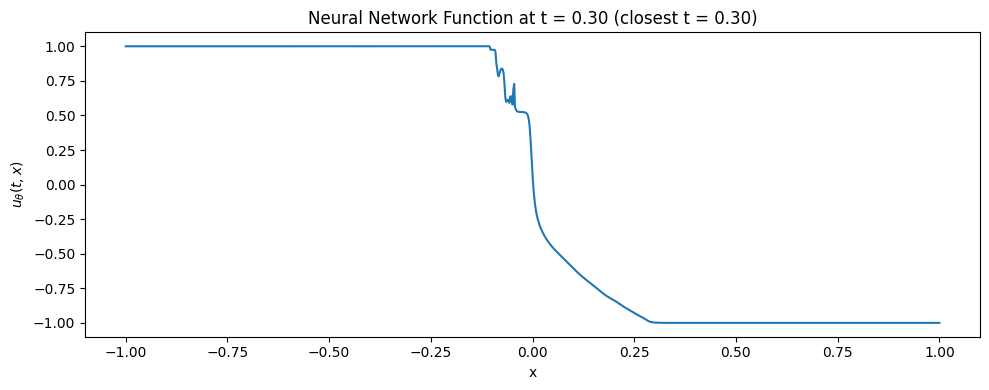

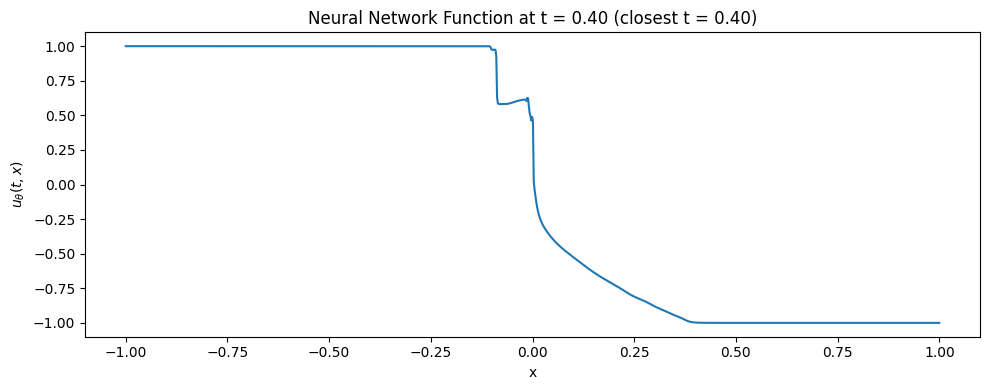

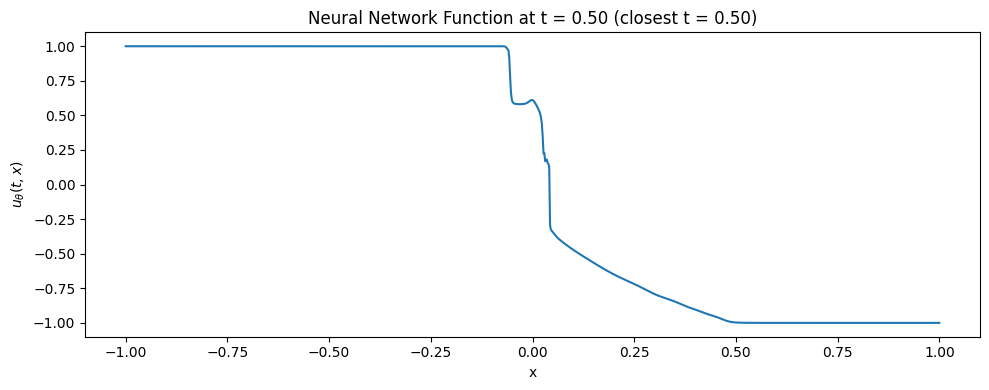

In [5]:
# optProb.train_process_stage2()
from my_helpers import plot_u_theta
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, ts=[0.1*i for i in range(6)])  # Plot initial model state


In [18]:
compute_errors(optProb.model, file_path='data/burgers_sin_ref.npz')

(np.float64(0.013388077580121584), np.float64(0.011679391725314864))

In [26]:
pwd

'/Users/haoli/Desktop/Conservation_law/NN-HCL/Code'

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


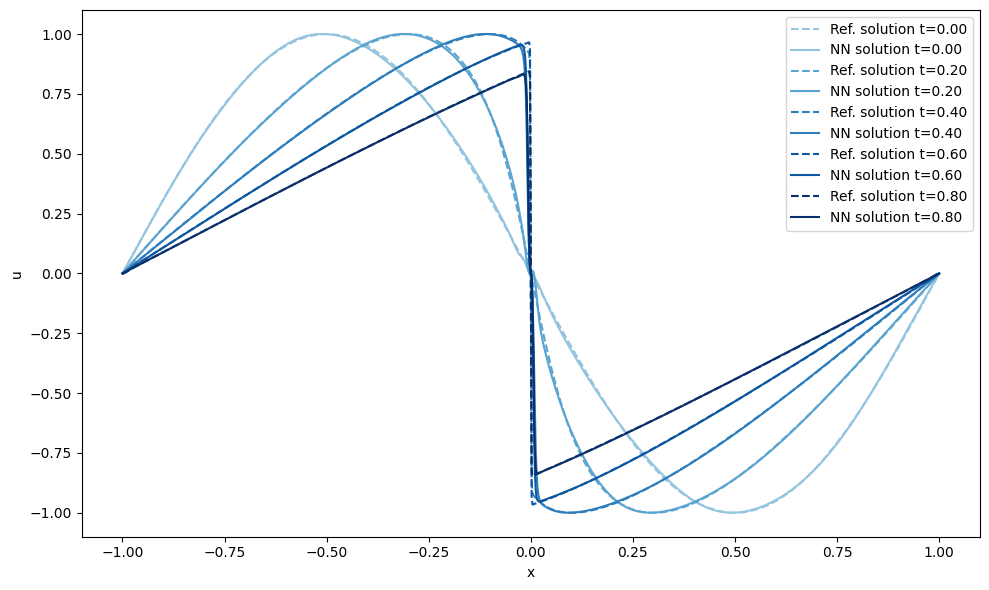

In [31]:
ts = [i*0.2 for i in range(5)]
plot_comparison_together(optProb.model, file_path='data/burgers_sin_ref.npz', ts=ts)

In [27]:
def compute_errors(model, file_path='data/burgers_sin_ref.npz', params=None, T=None):
    """
    Compute the relative error at time T and the space-time relative error between
    the neural network approximation u* and the numerical solution u.

    Args:
        model: Flax model instance representing u_theta.
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: '/data/burgers_sin_ref.npz').
        params: Parameters (pytree) of the neural network (default: None).
        T: The final time for the error at T. If None, uses the maximum time in the data (default: None).

    Returns:
        err_T: Relative error at time T.
        err_spacetime: Space-time relative error.
    """
    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    if T is None:
        T = times[-1]

    # Create grid for evaluation (matching the numerical grid)
    t_grid, x_grid = np.meshgrid(times, x, indexing='ij')  # Shapes: (n_t, n_x)
    tx_points = np.stack([t_grid.ravel(), x_grid.ravel()], axis=1)  # Shape: (n_t * n_x, 2)

    # Evaluate the neural network on the grid points
    if params is None:
        u_star_values = model.forward(tx_points)
    else:
        u_star_values = model(params, tx_points)  # Assuming shape: (n_points, 1) or (n_points,)
    u_star_values = np.asarray(u_star_values).squeeze()  # Ensure it's 1D array
    u_star = u_star_values.reshape(len(times), len(x))  # Shape: (n_t, n_x)

    # Compute relative error at t = T
    idx_T = np.argmin(np.abs(times - T))
    u_T = u_num[idx_T, :]
    u_star_T = u_star[idx_T, :]
    num_T = np.trapezoid(np.abs(u_star_T - u_T), x)
    den_T = np.trapezoid(np.abs(u_T), x)
    err_T = num_T / den_T if den_T != 0 else np.inf

    # Compute space-time relative error
    abs_diff = np.abs(u_star - u_num)  # Shape: (n_t, n_x)
    abs_u = np.abs(u_num)

    # Integrate over x for each t
    int_x_abs_diff = np.trapezoid(abs_diff, x, axis=1)  # Shape: (n_t,)
    int_x_abs_u = np.trapezoid(abs_u, x, axis=1)

    # Integrate over t
    spacetime_num = np.trapezoid(int_x_abs_diff, times)
    spacetime_den = np.trapezoid(int_x_abs_u, times)
    err_spacetime = spacetime_num / spacetime_den if spacetime_den != 0 else np.inf

    return err_T, err_spacetime

# Example usage (assuming model and params are defined):
# err_T, err_spacetime = compute_errors(model, params=params)
# print(f"Relative error at T: {err_T}")
# print(f"Space-time relative error: {err_spacetime}")


def plot_comparison_seperate(model, params=None, file_path='data/burgers_sin_ref.npz', ts=None):
    """
    Plot both the neural network solution and the numerical solution for each timestamp in ts,
    with both solutions overlaid on the same axes in subplots (one subplot per timestamp).

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network (default: None).
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: '/data/burgers_sin_ref.npz').
        ts: List or array of timestamps for which to plot the solutions (default: None).
    """
    if ts is None:
        ts = []
    if not ts:
        print("No timestamps provided. Nothing to plot.")
        return

    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    # Create subplots: one for each timestamp
    fig, axs = plt.subplots(len(ts), 1, figsize=(10, 4 * len(ts)), squeeze=False)
    axs = axs.flatten()  # Ensure axs is iterable even for len(ts)=1

    for i, t_val in enumerate(ts):
        # Numerical solution: find closest time index
        idx = np.argmin(np.abs(times - t_val))
        u_num_t = u_num[idx, :]

        # Neural network solution: evaluate at exact t_val on the same x grid
        x_jnp = jnp.asarray(x)
        t_jnp = jnp.full_like(x_jnp, t_val)
        tx_points = jnp.stack([t_jnp, x_jnp], axis=1)  # Shape: (n_x, 2)

        if params is None:
            u_nn_values = model.forward(tx_points)
        else:
            u_nn_values = model(params, tx_points)
        u_nn_t = np.asarray(u_nn_values).squeeze()  # Shape: (n_x,)

        # Plot both on the same axes
        ax = axs[i]
        ax.plot(x, u_num_t, label='Numerical', linewidth=2)
        ax.plot(x, u_nn_t, label='Neural Network', linestyle='--', linewidth=2)
        ax.legend()
        ax.set_xlabel('x')
        ax.set_ylabel('u')
        ax.set_title(f'Solutions at t = {t_val:.2f} (numerical closest t = {times[idx]:.2f})')

    plt.tight_layout()
    plt.show()


In [30]:
def plot_comparison_together(model, params=None, file_path='data/burgers_sin_ref.npz', ts=None, save_path='data/sine_wave_plot_together.eps', title=None):
    """
    Plot both the neural network solution (solid line) and the numerical solution (dashed line)
    for each timestamp in ts, with all comparisons overlaid on the same single figure. For each
    time, the pair of lines (numerical and neural) share the same color, progressing from light
    to dark as time increases.

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network (default: None).
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: '/burgers_sin_ref.npz').
        ts: List or array of timestamps for which to plot the solutions (default: None).
    """
    if ts is None:
        ts = []
    if not ts:
        print("No timestamps provided. Nothing to plot.")
        return

    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    # Create a single figure and axes
    fig, ax = plt.subplots(figsize=(10, 6))

    # Get colormap (light to dark blue)
    cmap = plt.cm.Blues

    # Normalize times for color mapping
    ts_array = np.array(ts)
    min_t = ts_array.min()
    max_t = ts_array.max()
    if min_t == max_t:
        norms = np.full(len(ts), 0.5)  # Medium color if all times are the same
    else:
        norms = 0.6*(ts_array - min_t) / (max_t - min_t) + 0.4

    for i, t_val in enumerate(ts):
        norm = norms[i]
        color = cmap(norm)

        # Numerical solution: find closest time index
        idx = np.argmin(np.abs(times - t_val))
        u_num_t = u_num[idx, :]

        # Neural network solution: evaluate at exact t_val on the same x grid
        x_jnp = jnp.asarray(x)
        t_jnp = jnp.full_like(x_jnp, t_val)
        tx_points = jnp.stack([t_jnp, x_jnp], axis=1)  # Shape: (n_x, 2)

        if params is None:
            u_nn_values = model.forward(tx_points)
        else:
            u_nn_values = model(params, tx_points)
        u_nn_t = np.asarray(u_nn_values).squeeze()  # Shape: (n_x,)

        # Plot both on the same axes with same color
        ax.plot(x, u_num_t, linestyle='--', color=color, label=f'Ref. solution t={t_val:.2f}')
        ax.plot(x, u_nn_t, linestyle='-', color=color, label=f'NN solution t={t_val:.2f}')

    ax.legend()
    ax.set_xlabel('x')
    ax.set_ylabel('u')
    if title is not None:
        ax.set_title(title)

    plt.tight_layout()
    plt.savefig(save_path, format='eps', bbox_inches='tight')
    plt.show()


In [3]:
print(os.environ.get('ENABLE_PJRT_COMPATIBILITY'))

1
